In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from sklearn.base import BaseEstimator, TransformerMixin

#################################################################
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.preprocessing import StandardScaler
from torch.utils.data import DataLoader, Dataset
from tqdm import tqdm

plt.style.use("dark_background")

In [2]:
from fetures_for_inference import create_features

In [3]:
device = "cuda" if torch.cuda.is_available() else "cpu"
device

'cuda'

In [4]:
SEED = 42
X_cols = [
    "FamilyID",
    "Pclass",
    "Sex",
    "Embarked",
    "Initial",
    "Age_band",
    "Rich_Woman",
    "Alone",
    "Family_size",
    "Fare_cat",
    "Age*Class",
]

In [5]:
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

In [6]:
data = pd.read_csv("train_data.csv")

In [7]:
class EarlyStopping:
    def __init__(self, mode="max", patience=10, threshold=0.001, threshold_mode="abs"):
        self.mode = mode
        self.patience = patience
        self.threshold = threshold
        self.threshold_mode = threshold_mode
        self.count = 0
        self.best = None

    def __call__(self, trecked_param):
        current = float(trecked_param)

        if self.best is None:
            self.best = current
            return False

        if self.changed_better(current, self.best):
            self.best = current
            self.count = 0
        else:
            self.count += 1

        if self.count >= self.patience:
            self.count = 0
            return True
        return False

    def changed_better(self, current, best):
        return current > best + self.threshold

In [8]:
class MyModel(nn.Module):
    def __init__(self, input, output):
        super().__init__()
        self.layer_1 = nn.Linear(input, 128)
        self.layer_2 = nn.Linear(128, output)
        self.dropout = nn.Dropout(0.5)
        self.act = nn.ReLU()

    def forward(self, x):
        x = self.layer_1(x)
        x = self.act(x)
        x = self.dropout(x)
        out = self.layer_2(x)
        return out

In [9]:
class FeatureTranformer(BaseEstimator, TransformerMixin):
    def __init__(self, m: int = 2, y_: float = 0.38):
        self.X_cols = X_cols
        self.m = m
        self.y_ = y_

    def fit(self, X, y):
        # обучаемся только на train fold
        # сохраняем stat
        self.y_ = y.mean()
        X = pd.concat([X, y], axis=1)
        X["Family_TE"] = (
            X["FamilyID"].map(X.groupby("FamilyID")["Survived"].sum())
            + self.m * self.y_
        ) / (X["Family_size"] + 1 + self.m)
        self.stat = X[["FamilyID", "Family_TE"]].drop_duplicates(subset=["FamilyID"])
        self.stat = self.stat.set_index("FamilyID")["Family_TE"]
        return self

    def transform(self, X):
        # используем сохранённые stat
        X_transformed = X.copy()
        X_transformed["Family_TE"] = (
            X_transformed["FamilyID"].map(self.stat).fillna(self.y_)
        )
        X_transformed = X_transformed.drop(columns=["FamilyID"])

        return X_transformed

    def fit_transform(self, X, y=None):
        # специальная логика получения train-feature без leakage

        self.fit(X, y)
        X_transformed = pd.concat([X, y], axis=1)
        X_transformed["Family_TE"] = (
            X_transformed["FamilyID"].map(
                X_transformed.groupby("FamilyID")["Survived"].sum()
            )
            - X_transformed["Survived"]
            + self.m * self.y_
        ) / (X_transformed["Family_size"] + self.m)

        X_transformed = X_transformed.drop(columns=["FamilyID", "Survived"])

        return X_transformed

In [10]:
class TableDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)

        self.y = torch.tensor(y, dtype=torch.long)

    def __len__(self):
        # Возвращает общее количество строк в таблице
        return len(self.X)

    def __getitem__(self, idx):
        # Возвращает одну строку (признаки и таргет) по индексу
        return self.X[idx], self.y[idx]

In [11]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

In [12]:
X = data[X_cols]
y = data["Survived"]

In [13]:
X_dev, X_holdout, y_dev, y_holdout = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=SEED,
)

## Пометка дурачку
Обычно ты не выбираешь одну из пяти сетей, а обучаешь новую финальную модель на всех данных, использованных в кросс-валидации, с уже выбранными настройками.
Кросс-валидация помогает выбрать архитектуру и способ обучения, а итоговое обучение — получить одну сеть для инференса.
Порядок такой:
1. Заранее откладываешь тестовую выборку. Она не участвует в выборе параметров.
2. На остальных данных проводишь кросс-валидацию. Сравниваешь архитектуры, learning rate, регуляризацию и другие настройки по средним метрикам пяти фолдов.
3. Фиксируешь лучшие настройки.
4. Создаёшь новую сеть и обучаешь её на всех пяти частях вместе. Тестовая выборка по-прежнему остаётся отдельно.
5. Один раз оцениваешь финальную сеть на тесте, сохраняешь веса и используешь для инференса.

Разделить цикл сv на эпохи и фолды

In [14]:
def run_epoch(
    model,
    train_loader,
    val_loader,
    loss_classification,
    opt_classification,
    flag="train_val",
):
    train_loss = []
    train_acc = []
    val_loss = []
    val_acc = []

    if flag in ("train_val", "train"):
        model.train()

        loss_sum = 0.0
        total_samples = 0
        true_answer = 0

        for x, targets in tqdm(train_loader, leave=False):
            x = x.to(device)
            targets = targets.to(device)

            opt_classification.zero_grad()

            pred = model(x)
            loss = loss_classification(pred, targets)

            loss.backward()
            opt_classification.step()

            batch_size = targets.size(0)

            loss_sum += loss.item() * batch_size
            total_samples += batch_size
            true_answer += (pred.argmax(dim=1) == targets).sum().item()

        train_loss.append(loss_sum / total_samples)
        train_acc.append(true_answer / total_samples)

    if flag in ("train_val", "val"):
        model.eval()

        # Отдельные накопители для валидации
        loss_sum = 0.0
        total_samples = 0
        true_answer = 0

        with torch.no_grad():
            for x, targets in val_loader:
                x = x.to(device)
                targets = targets.to(device)

                pred = model(x)
                loss = loss_classification(pred, targets)

                batch_size = targets.size(0)

                loss_sum += loss.item() * batch_size
                total_samples += batch_size
                true_answer += (pred.argmax(dim=1) == targets).sum().item()

        val_loss.append(loss_sum / total_samples)
        val_acc.append(true_answer / total_samples)

    return train_loss, train_acc, val_loss, val_acc

In [15]:
# Hyperparams
EPOCHS = 30  # Кол-во эпох обучения
# lr_scheduler
lr_scheduler_patience = (
    2  # Кол-во эпох без изменения скорости обучения, четное разумеется
)
lr_scheduler_gamma = 0.9  # Насколько измениться скорость обучения
# EarlyStopping
early_stopping_patience = 15  # Кол-во эпох без измененния отслеживаемой переменной
early_stopping_threshold = 0.01  # Насколько должна измениться отслеживаемая переменная
# Adam
optim_lr = 0.01
# Dataloader
loader_batch_size = 16  # Размер батча
# Saving threshold
saving_threshold = 0.005

In [16]:
# Metrics
train_loss_all_folds = []
train_acc_all_folds = []
val_loss_all_folds = []
val_acc_all_folds = []
model_list = []

mean_fold_val_loss = []
learning_rate_all_folds = []

# ------
best_epochs_for_folds = []
best_scores_for_folds = []

In [17]:
for fold, (train_idx, val_idx) in enumerate(skf.split(X_dev, y_dev), 1):
    X_train, X_val = X_dev.iloc[train_idx], X_dev.iloc[val_idx]
    y_train, y_val = y_dev.iloc[train_idx], y_dev.iloc[val_idx]

    feature_trandform = FeatureTranformer()
    scaler = StandardScaler()
    early_stopping = EarlyStopping(
        mode="max",
        patience=early_stopping_patience,
        threshold=early_stopping_threshold,
        threshold_mode="abs",
    )

    X_train_transformed = feature_trandform.fit_transform(X_train, y_train)
    X_val_transformed = feature_trandform.transform(X_val)

    X_train_scaled = scaler.fit_transform(X_train_transformed)
    X_val_scaled = scaler.transform(X_val_transformed)

    # Создаем модель
    model_classification = MyModel(X_train_scaled.shape[1], 2).to(device)

    # Определяем функцию потерь и оптимизатор градиентного спуска
    loss_classification = nn.CrossEntropyLoss()
    opt_classification = torch.optim.Adam(
        model_classification.parameters(), lr=optim_lr
    )
    lr_scheduler = torch.optim.lr_scheduler.ExponentialLR(
        opt_classification, gamma=lr_scheduler_gamma
    )

    train_data = TableDataset(X_train_scaled, y_train.values)
    val_data = TableDataset(X_val_scaled, y_val.values)

    train_loader = DataLoader(train_data, batch_size=loader_batch_size, shuffle=True)
    val_loader = DataLoader(val_data, batch_size=loader_batch_size, shuffle=True)

    best_score = None
    best_epoch = None

    epochs_train_loss = []
    epochs_train_acc = []
    epochs_val_loss = []
    epochs_val_acc = []

    learning_rate_epoch = []

    for epoch in range(EPOCHS):
        train_loss, train_acc, val_loss, val_acc = run_epoch(
            model_classification,
            train_loader,
            val_loader,
            loss_classification,
            opt_classification,
        )

        epochs_train_loss.append(train_loss)
        epochs_train_acc.append(train_acc)
        epochs_val_loss.append(val_loss)
        epochs_val_acc.append(val_acc)

        mean_val_acc = np.mean(val_acc)

        if epoch % lr_scheduler_patience == 0:
            lr_scheduler.step()
        learning_rate_epoch.append(lr_scheduler._last_lr[0])

        if best_score is None:
            best_score = mean_val_acc

        if best_epoch is None:
            best_epoch = epoch + 1

        if mean_val_acc - best_score >= saving_threshold:
            best_score = mean_val_acc
            best_epoch = epoch + 1
            pipeline_state = {
                "feature_transformer": feature_trandform,
                "scaler": scaler,
                "model_state_dict": model_classification.state_dict(),
            }
            torch.save(
                pipeline_state,
                f"./DL_Models/full_pipeline_epoch--{epoch + 1}, fold--{fold}.pt",
            )
            print(f"сохранили пайплайн на эпохе {epoch + 1}")

        if epoch + 1 == 1:
            pipeline_state = {
                "feature_transformer": feature_trandform,
                "scaler": scaler,
                "model_state_dict": model_classification.state_dict(),
            }
            torch.save(
                pipeline_state,
                f"./DL_Models/full_pipeline_epoch--{epoch + 1}, fold--{fold}.pt",
            )

        if early_stopping(mean_val_acc):
            print(f"\033[31mОбучение остановлено на {epoch + 1} эпохе.\033[0m")
            break

    final_pipeline = torch.load(
        f"./DL_Models/full_pipeline_epoch--{best_epoch}, fold--{fold}.pt",
        map_location=device,
        weights_only=False,
    )
    final_model = MyModel(11, 2).to(device)
    final_model.load_state_dict(final_pipeline["model_state_dict"])

    final_feature = final_pipeline["feature_transformer"]
    final_scaler = final_pipeline["scaler"]

    _, _, best_fold_loss, best_fold_acc = run_epoch(
        final_model, None, val_loader, loss_classification, None, flag="val"
    )

    best_epochs_for_folds.append(best_epoch)
    best_scores_for_folds.append(best_score)

    train_loss_all_folds.append(epochs_train_loss)
    train_acc_all_folds.append(epochs_train_acc)
    val_loss_all_folds.append(epochs_val_loss)
    val_acc_all_folds.append(epochs_val_acc)

    learning_rate_all_folds.append(learning_rate_epoch)

сохранили пайплайн на эпохе 2


сохранили пайплайн на эпохе 12


сохранили пайплайн на эпохе 17


сохранили пайплайн на эпохе 2


сохранили пайплайн на эпохе 4


сохранили пайплайн на эпохе 5


... (4 outputs left out)

Обучение остановлено на 19 эпохе.


Обучение остановлено на 16 эпохе.


сохранили пайплайн на эпохе 2


Обучение остановлено на 17 эпохе.


In [18]:
best_scores_for_folds

[np.float64(0.8601398601398601),
 np.float64(0.8461538461538461),
 np.float64(0.8591549295774648),
 np.float64(0.8380281690140845),
 np.float64(0.8380281690140845)]

In [19]:
# EPOCHS = 30
# train_loss_all_folds = []
# train_acc_all_folds = []
# val_loss_all_folds = []
# val_acc_all_folds = []
# model_list = []

# mean_fold_val_loss = []
# learning_rate_all_folds = []

# cv_best_epochs = []

# lr_list = []
# best_loss = None

# count = 0

In [20]:
# for fold, (train_idx, val_idx) in enumerate(skf.split(X, y), 1):
#     best_score = None
#     best_epoch = None

#     train_loss = []
#     train_acc = []
#     val_loss = []
#     val_acc = []
#     learning_rate_=[]

#     X_train, X_val = X.iloc[train_idx], X.iloc[val_idx]
#     y_train, y_val = y.iloc[train_idx], y.iloc[val_idx]

#     feature_trandform = FeatureTranformer()
#     scaler = StandardScaler()
#     early_stopping = EarlyStopping(mode = 'max',patience = 15, threshold = 0.01, threshold_mode = 'abs') #последнее

#     X_train_transformed = feature_trandform.fit_transform(X_train,y_train)
#     X_val_transformed = feature_trandform.transform(X_val)

#     X_train_scaled = scaler.fit_transform(X_train_transformed)
#     X_val_scaled = scaler.transform(X_val_transformed)

#     #Создаем модель
#     model_classification = MyModel(X_train_scaled.shape[1],2).to(device)

#     #Определяем функцию потерь и оптимизатор градиентного спуска
#     loss_classification = nn.CrossEntropyLoss()
#     opt_classification = torch.optim.Adam(model_classification.parameters(), lr = 0.01)

#     lr_scheduler = torch.optim.lr_scheduler.ExponentialLR(opt_classification,gamma=0.1)

#     # lr_scheduler =  torch.optim.lr_scheduler.ReduceLROnPlateau(opt_classification, # оптимизатор
#     #                                                        mode = 'max',# max или min - cледим чтобы остлеживаемый параметр увеличивался или уменьшался
#     #                                                        factor=0.001, # коэффициент на который будет умножен lr
#     #                                                        patience=10,# кол-во эпох без улучшения отслеживаемого параметра (рекомендуется от 5 до 10)
#     #                                                        threshold=0.001, # порог, на который должен измениться отслеживаемый параметр
#     #                                                        threshold_mode='abs',# rel или abs, если rel то отслеживаемый параметр должен измениться на threshold %, если abs то прсото изменненние на threshold
#     #                                                        cooldown=0,# кол-во переиодов ожидания после уменьшения lr
#     #                                                        min_lr=0.00001, # минимальное значение скорости обучения
#     #                                                        eps=1e-8) # минимальное значение между старым и новым lr

#     print(type(y_train))
#     print(type(y_val))
#     train_data = TableDataset(X_train_scaled,y_train.values)
#     val_data = TableDataset(X_val_scaled,y_val.values)

#     train_loader = DataLoader(train_data,batch_size=16, shuffle=True)
#     val_loader = DataLoader(val_data,batch_size=16, shuffle=True)

#     for epoch in range(EPOCHS):
#         mean_val_acc_epoch = []
#         #Тренировка модели
#         model_classification.train()
#         running_train_loss = []
#         true_answer = 0

#         train_loop =tqdm(train_loader, leave=False)
#         for x, targets in train_loop:
#             x = x.to(device)
#             targets = targets.to(device)

#             pred = model_classification(x)
#             loss = loss_classification(pred, targets)

#             #Обратный проход
#             opt_classification.zero_grad()
#             loss.backward()
#             #Шаг оптимизации
#             opt_classification.step()

#             running_train_loss.append(loss.item())
#             mean_train_loss = np.mean(running_train_loss)
#             true_answer += (pred.argmax(dim=1) == targets).sum().item()

#             train_loop.set_description(f'Epoch [{epoch+1}/{EPOCHS}], train_loss = {mean_train_loss:.4f}')

#         running_train_acc = true_answer/len(train_data)

#         #Сохраненние значения функции потерь и метрики
#         train_loss.append(mean_train_loss)
#         train_acc.append(running_train_acc)

#         #Проверка модели (валидация)
#         model_classification.eval()
#         with torch.no_grad(): #запрет на вычисление градиента внутри этого менеджера контекста
#             running_val_loss = []
#             true_answer = 0
#             for x, targets in val_loader:
#                 x = x.to(device)
#                 targets = targets.to(device)

#                 pred = model_classification(x)
#                 loss = loss_classification(pred, targets)

#                 running_val_loss.append(loss.item())
#                 mean_val_loss = np.mean(running_val_loss)

#                 true_answer += (pred.argmax(dim=1) == targets).sum().item()

#             #Расчет значения метрики
#             running_val_acc = true_answer/len(val_data)

#             #Сохраненние значения функции потерь и метрики
#             val_loss.append(mean_val_loss)
#             val_acc.append(running_val_acc)

#             mean_val_acc_epoch.append(running_val_acc)

#             print(f"Epoch [{epoch+1}/{EPOCHS}], train_loss={mean_train_loss:.4f}, train_acc={running_train_acc:.4f}, val_loss={mean_val_loss:.4f}, val_acc={running_val_acc:.4f}")

#         if epoch % 2 == 0:
#             lr_scheduler.step(running_val_acc)
#         learning_rate_.append(lr_scheduler._last_lr[0])

#         if best_score is None:
#             best_score = np.mean(mean_val_acc_epoch)

#         if best_epoch is None:
#             best_epoch = epoch

#         if np.mean(mean_val_acc_epoch) > best_score:
#             best_epoch = epoch


#         if early_stopping(running_val_acc):
#             print(f"\033[31mОбучение остановлено на {epoch + 1} эпохе.\033[0m")
#             break


#     cv_best_epochs.append(best_epoch)
#     mean_f_loss = np.mean(val_loss)
#     mean_fold_val_loss.append(mean_f_loss)

#     model_list.append({
#         'model':model_classification,
#         'scaler':scaler,
#         'feature':feature_trandform,
#         'loss':loss_classification})
#     print(f'fold {fold} loss: {mean_f_loss}')

#     train_loss_all_folds.append(train_loss)
#     train_acc_all_folds.append(train_acc)
#     val_loss_all_folds.append(val_loss)
#     val_acc_all_folds.append(val_acc)

#     learning_rate_all_folds.append(learning_rate_)

In [21]:
print(
    f"среднее для всех фолдов {np.mean(best_scores_for_folds)},стандартное отклоненние {np.std(best_scores_for_folds)}"
)

среднее для всех фолдов 0.848300994779868,стандартное отклоненние 0.009732818494691256


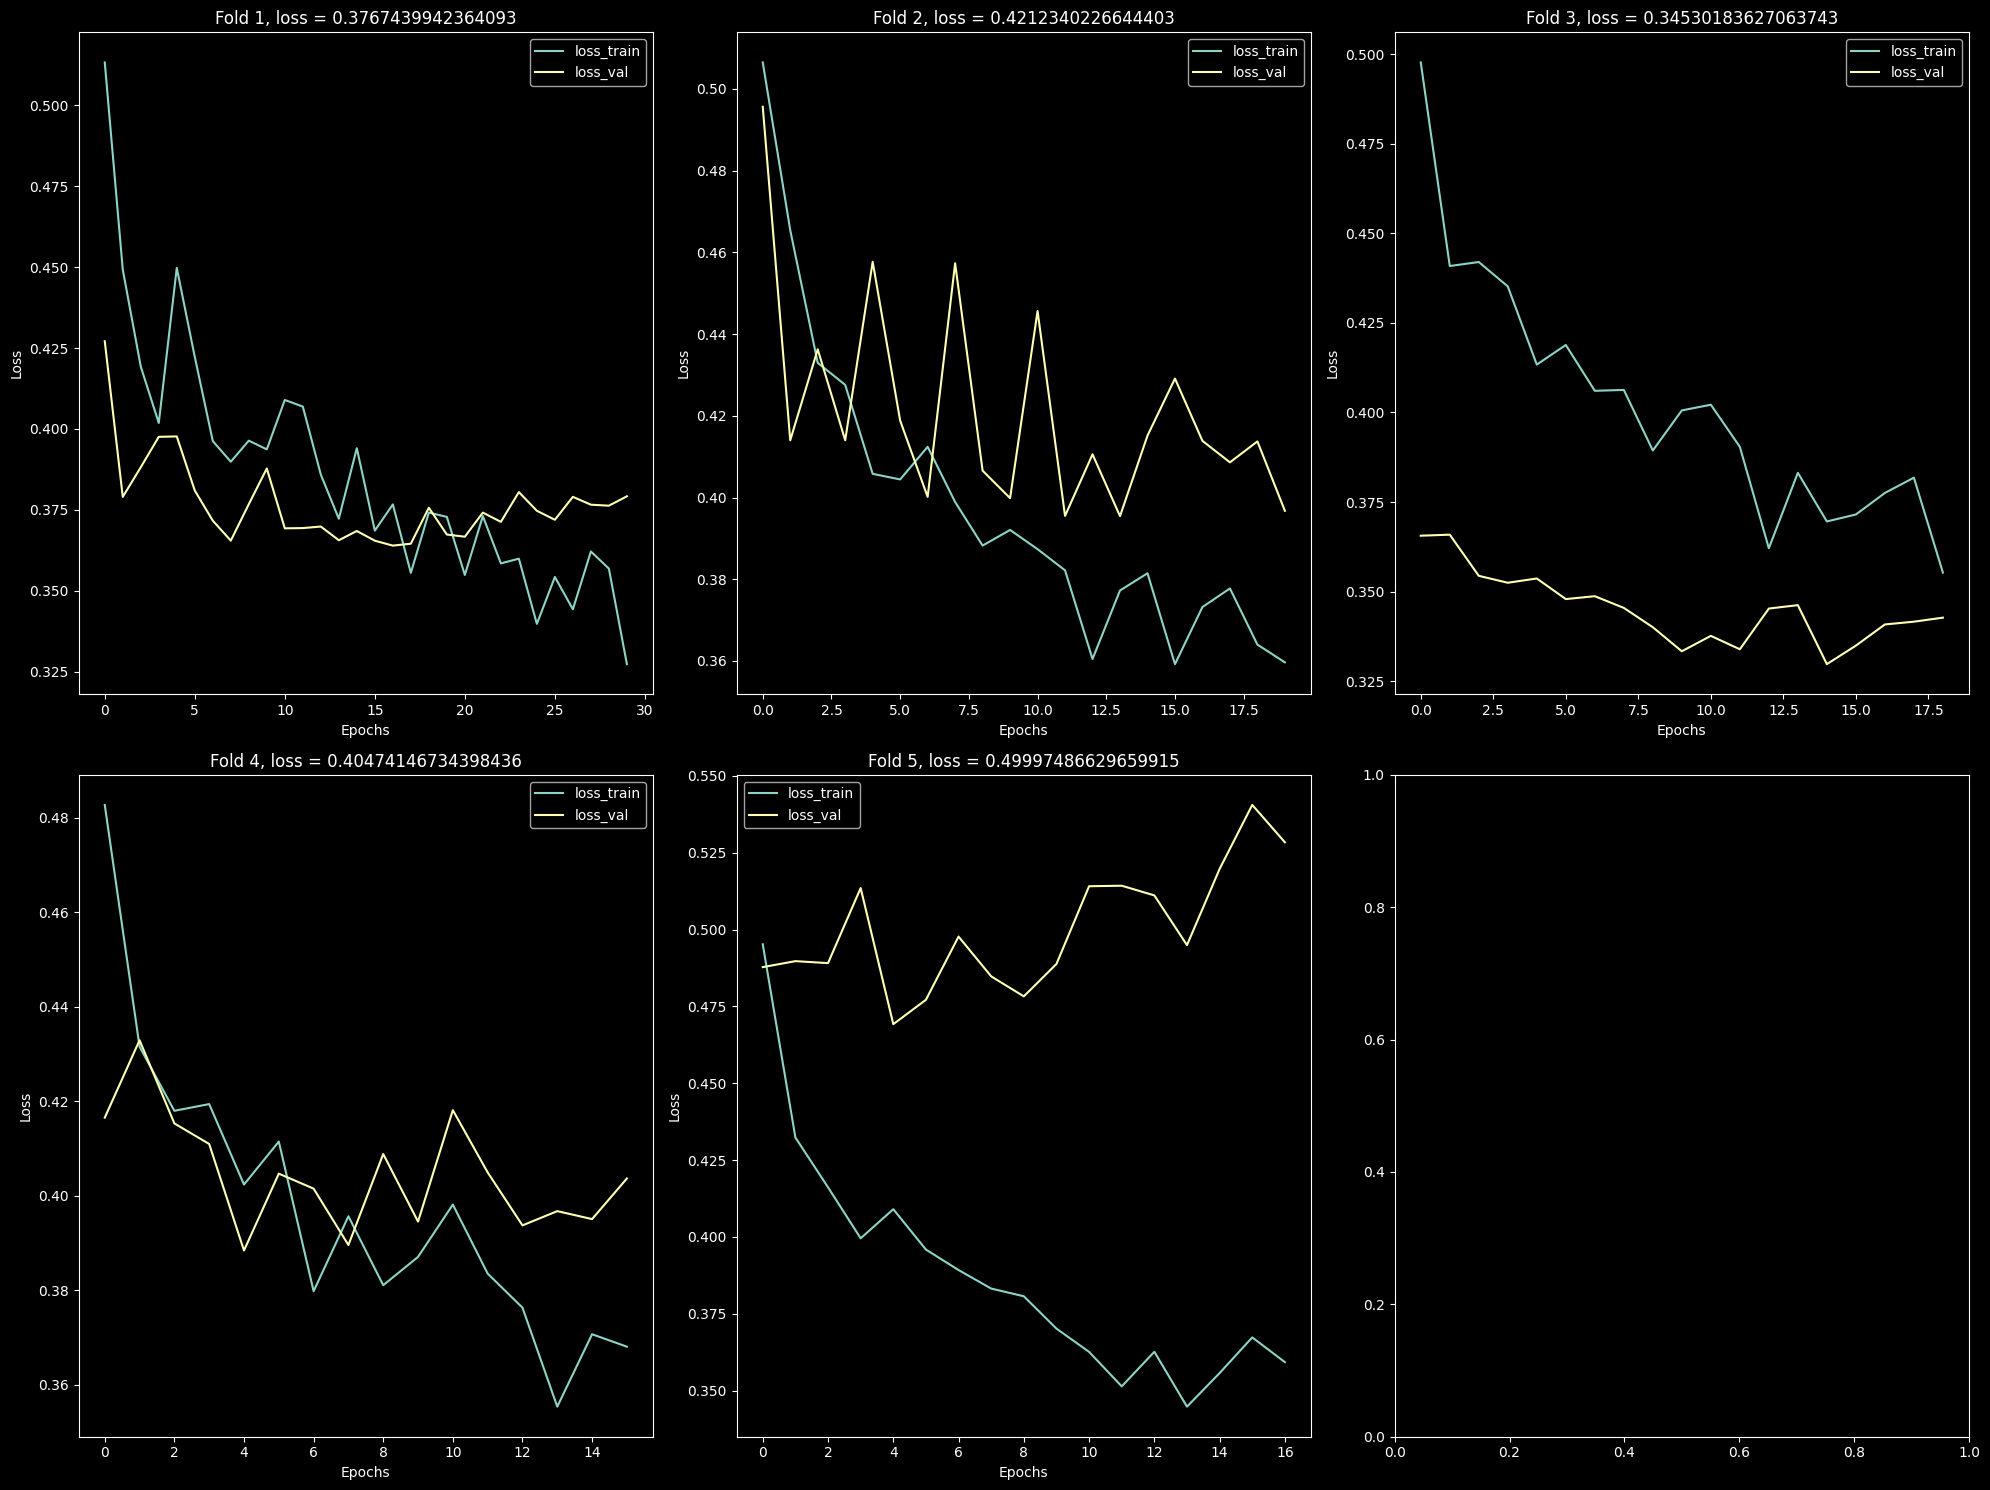

In [22]:
f, ax = plt.subplots(2, 3, figsize=(20, 15))

# Сглаживаем двумерный массив осей в одномерный, чтобы итерироваться по нему
ax_flat = ax.flatten()

for i, (train_loss, val_loss) in enumerate(
    zip(train_loss_all_folds, val_loss_all_folds)
):
    # Проверяем, чтобы не выйти за пределы количества сабплотов (максимум 6)
    if i >= len(ax_flat):
        break

    ax_flat[i].plot(train_loss, label="loss_train")
    ax_flat[i].plot(val_loss, label="loss_val")

    ax_flat[i].set_title(f"Fold {i + 1}, loss = {np.mean(val_loss)}")
    ax_flat[i].set_xlabel("Epochs")
    ax_flat[i].set_ylabel("Loss")
    ax_flat[i].legend()

plt.tight_layout()
plt.show()

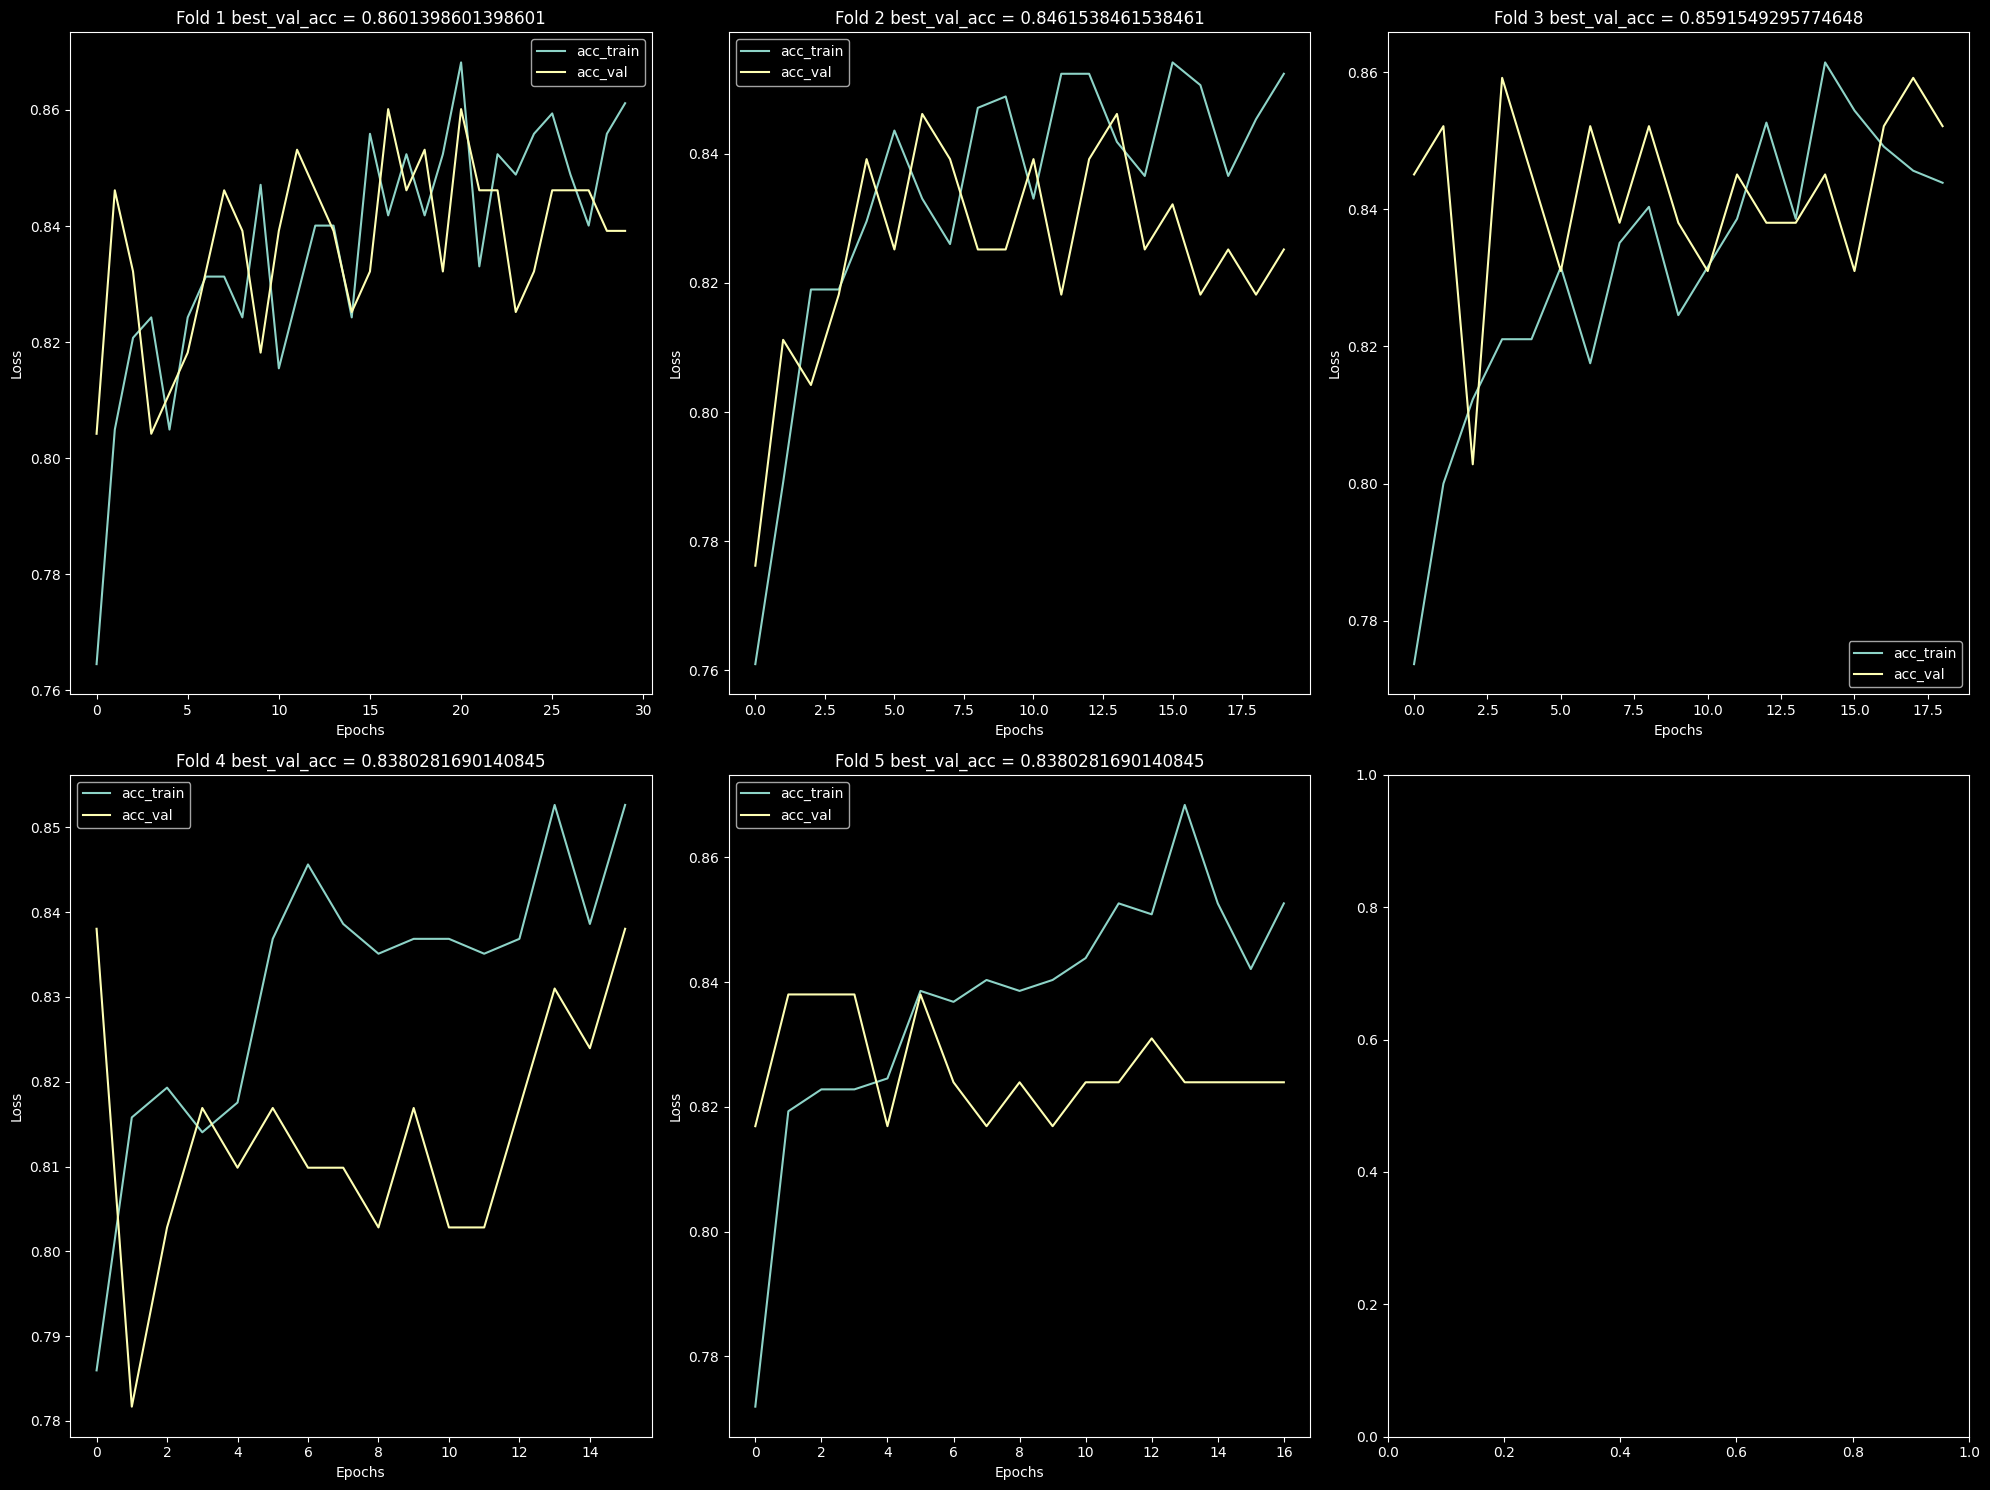

In [23]:
f, ax = plt.subplots(2, 3, figsize=(20, 15))

# Сглаживаем двумерный массив осей в одномерный, чтобы итерироваться по нему
ax_flat = ax.flatten()

for i, (train_acc, val_acc, best_score) in enumerate(
    zip(train_acc_all_folds, val_acc_all_folds, best_scores_for_folds)
):
    # Проверяем, чтобы не выйти за пределы количества сабплотов (максимум 6)
    if i >= len(ax_flat):
        break

    ax_flat[i].plot(train_acc, label="acc_train")
    ax_flat[i].plot(val_acc, label="acc_val")

    ax_flat[i].set_title(f"Fold {i + 1} best_val_acc = {best_score}")
    ax_flat[i].set_xlabel("Epochs")
    ax_flat[i].set_ylabel("Loss")
    ax_flat[i].legend()

plt.tight_layout()
plt.show()

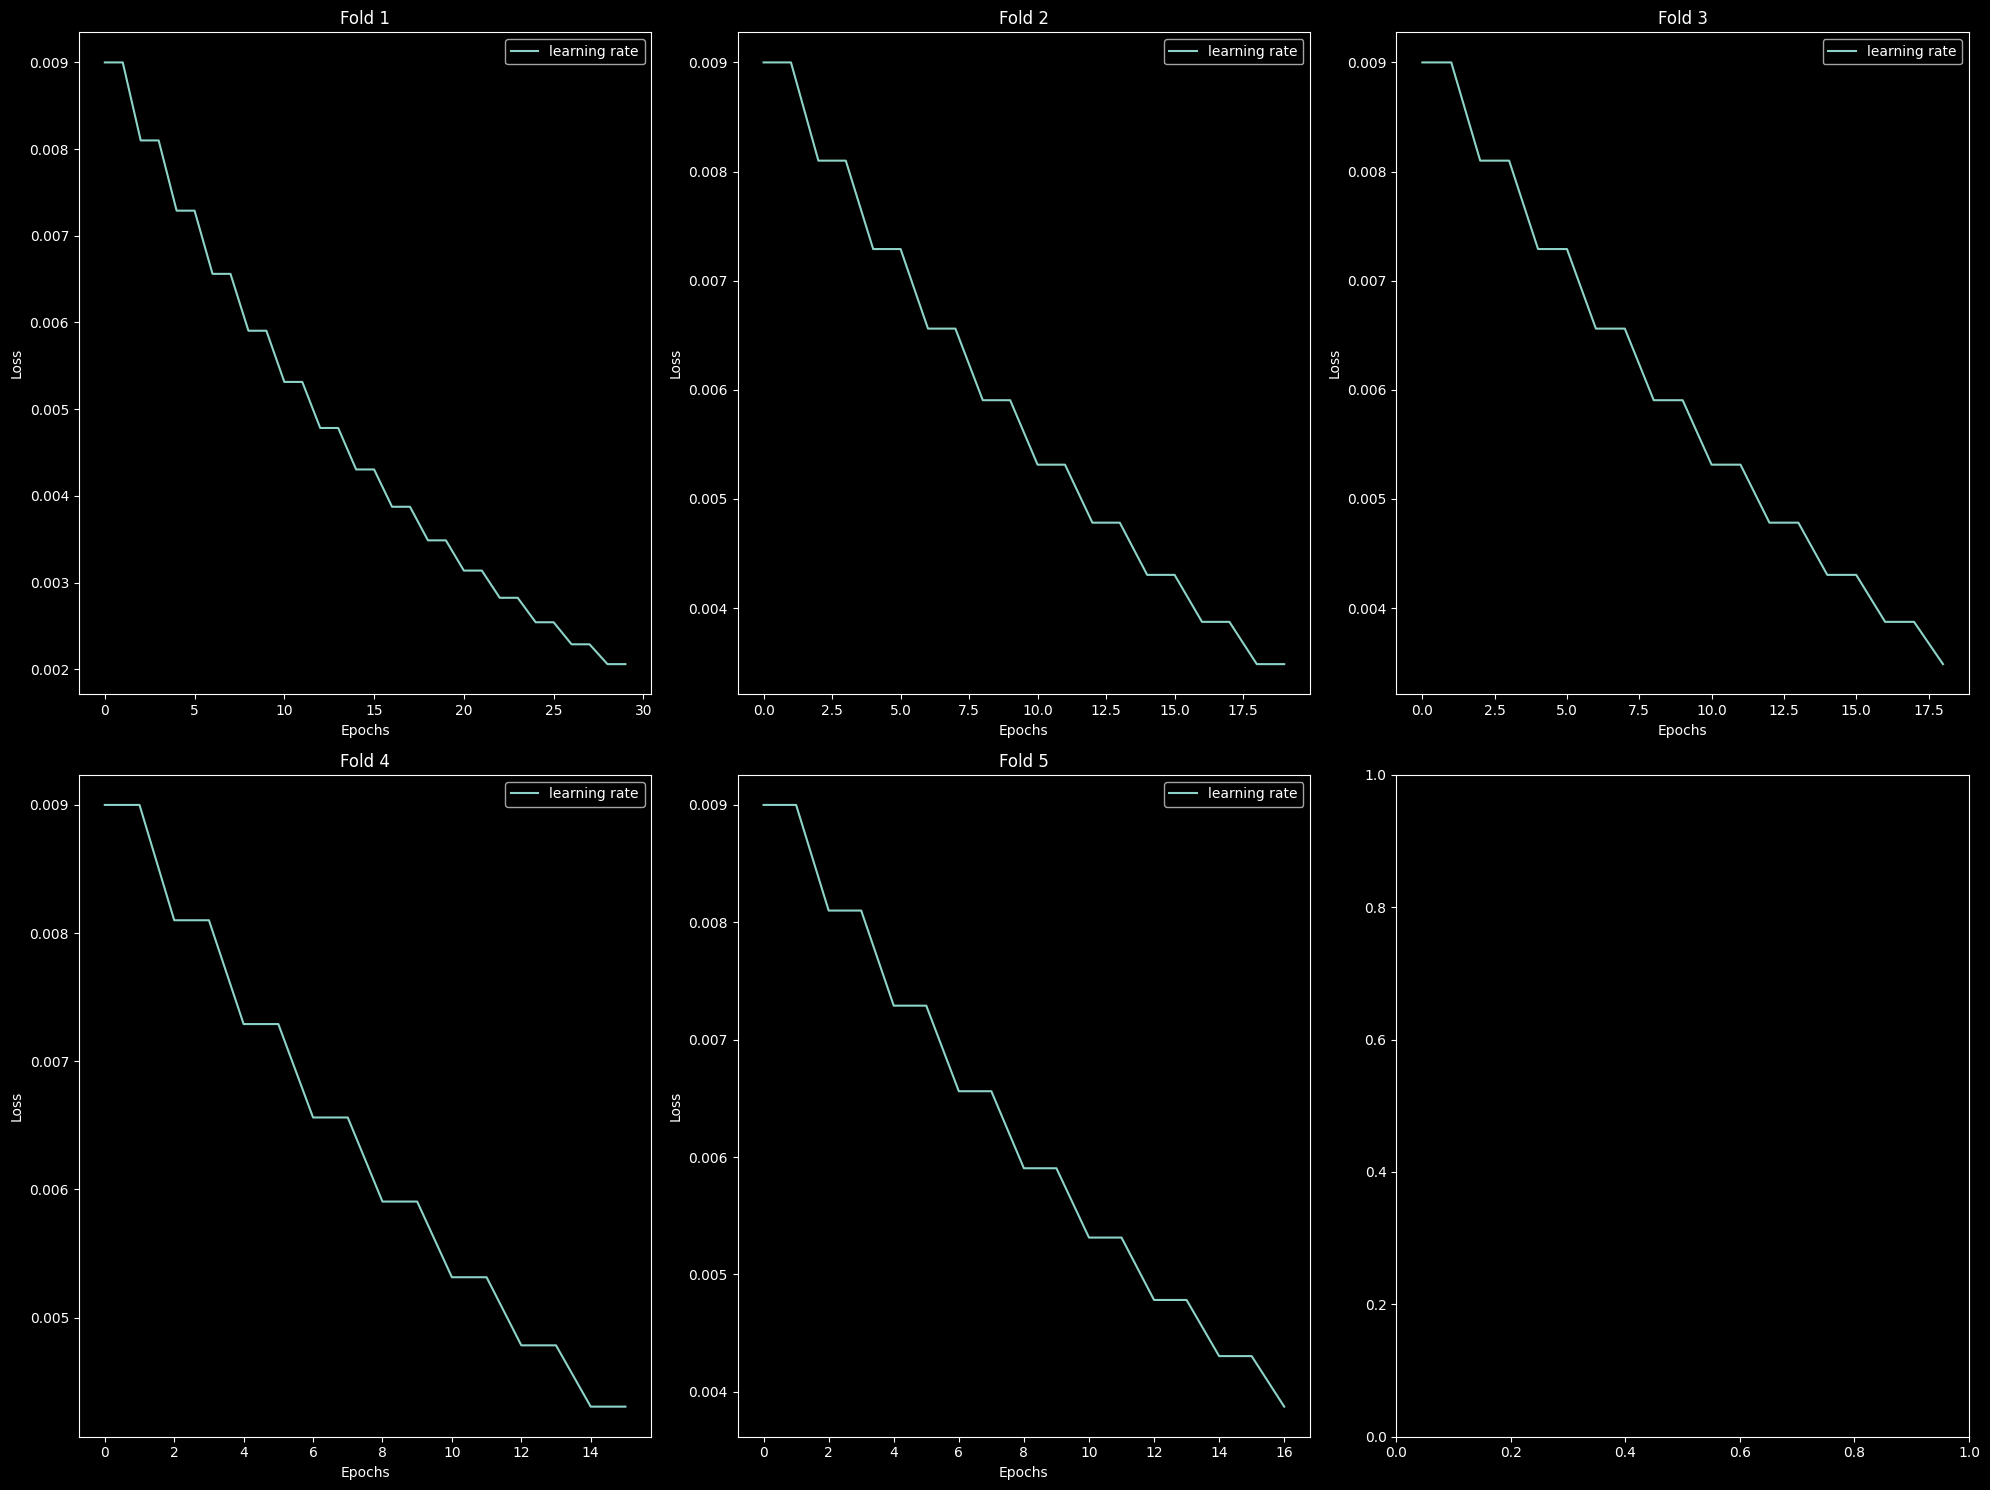

In [24]:
f, ax = plt.subplots(2, 3, figsize=(20, 15))

# Сглаживаем двумерный массив осей в одномерный, чтобы итерироваться по нему
ax_flat = ax.flatten()

for i, learning_rate in enumerate(learning_rate_all_folds):
    # Проверяем, чтобы не выйти за пределы количества сабплотов (максимум 6)
    if i >= len(ax_flat):
        break

    ax_flat[i].plot(learning_rate, label="learning rate")

    ax_flat[i].set_title(f"Fold {i + 1}")
    ax_flat[i].set_xlabel("Epochs")
    ax_flat[i].set_ylabel("Loss")
    ax_flat[i].legend()

plt.tight_layout()
plt.show()

In [35]:
np.median(best_epochs_for_folds)

np.float64(4.0)

## Обучение финальной модели

In [26]:
EPOCHS = np.int32(np.median(best_epochs_for_folds))

In [28]:
feature_trandform = FeatureTranformer()
scaler = StandardScaler()
early_stopping = EarlyStopping(
    mode="max",
    patience=early_stopping_patience,
    threshold=early_stopping_threshold,
    threshold_mode="abs",
)

X_train_transformed = feature_trandform.fit_transform(X, y)

X_train_scaled = scaler.fit_transform(X_train_transformed)

# Создаем модель
model_classification = MyModel(X_train_scaled.shape[1], 2).to(device)

# Определяем функцию потерь и оптимизатор градиентного спуска
loss_classification = nn.CrossEntropyLoss()
opt_classification = torch.optim.Adam(model_classification.parameters(), lr=optim_lr)
lr_scheduler = torch.optim.lr_scheduler.ExponentialLR(
    opt_classification, gamma=lr_scheduler_gamma
)

train_data = TableDataset(X_train_scaled, y.values)
train_loader = DataLoader(train_data, batch_size=loader_batch_size, shuffle=True)

best_score = None
best_epoch = None

epochs_train_loss = []
epochs_train_acc = []

learning_rate_epoch = []

for epoch in range(EPOCHS):
    train_loss, train_acc, val_loss, val_acc = run_epoch(
        model_classification,
        train_loader,
        val_loader,
        loss_classification,
        opt_classification,
        "train",
    )

    epochs_train_loss.append(train_loss)
    epochs_train_acc.append(train_acc)

    if epoch % lr_scheduler_patience == 0:
        lr_scheduler.step()
    learning_rate_epoch.append(lr_scheduler._last_lr[0])


pipeline_state = {
    "feature_transformer": feature_trandform,
    "scaler": scaler,
    "model_state_dict": model_classification.state_dict(),
}
torch.save(pipeline_state, f"./DL_Models/final_full_pipeline_epoch--{epoch + 1}.pt")

  0%|          | 0/56 [00:00<?, ?it/s]

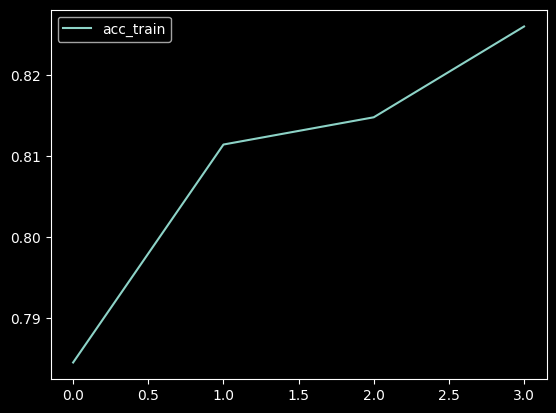

In [29]:
plt.plot(epochs_train_acc)
plt.legend(["acc_train", "acc_val"])
plt.show()

## Проверка финальной модели



In [ ]:
# final_pipeline = torch.load(r"C:\Users\user\3D Objects\code 2\Mentor_python\Block 2\Final_prodject\Titanic\DL_Models\final_full_pipeline_epoch--4.pt", map_location=device,weights_only = False)
# final_model = MyModel(11,2).to(device)
# final_model.load_state_dict(final_pipeline['model_state_dict'])

# final_feature = final_pipeline['feature_transformer']
# final_scaler = final_pipeline['scaler']

In [ ]:
# X_holdout_transformed = final_feature.transform(X_holdout)
# X_holdout_scaled = final_scaler.transform(X_holdout_transformed)

# dummy_y = np.zeros(len(X_holdout))

# test_data = TableDataset(X_holdout_scaled,dummy_y)
# test_loader = DataLoader(test_data, batch_size=16, shuffle=False)

# test_preds = []

# final_model.eval()
# with torch.no_grad():
#     running_test_loss = []
#     true_answer = 0
#     for x, targets in test_loader:
#         #Данные
#         x = x.to(device)
#         #Предсказания
#         pred = final_model(x)

#         binary_preds = pred.argmax(dim=1).cpu().numpy()

#         test_preds.append(binary_preds)


In [ ]:
# final_preds = np.concatenate(test_preds)

In [ ]:
# test_accuracy = accuracy_score(y_holdout.values,final_preds)
# print(test_accuracy)

0.7877094972067039


In [ ]:
# threshold =0.1
# if best_loss - mean_val_loss > threshold:
#     best_loss = mean_val_loss

#     pipeline_state = {
#     'feature_transformer': feature_trandform,          # Ваш кастомный объект
#     'scaler': scaler,                                   # Объекты sklearn сохраняются отлично
#     'model_state_dict': model_classification.state_dict() # Сохраняем только веса модели
# }
#     torch.save(pipeline_state,f"full_inference_pipeline_epoch{epoch+1}.pt")
#     print(f'сохранили пайплайн на эпохе {epoch + 1}')

## Проверка модели

In [30]:
final_pipeline = torch.load(
    r"C:\Users\user\3D Objects\code 2\Mentor_python\Block 2\Final_prodject\Titanic\DL_Models\final_full_pipeline_epoch--4.pt",
    map_location=device,
    weights_only=False,
)
final_model = MyModel(11, 2).to(device)
final_model.load_state_dict(final_pipeline["model_state_dict"])

final_feature = final_pipeline["feature_transformer"]
final_scaler = final_pipeline["scaler"]

In [31]:
test_df = pd.read_csv(
    r"C:\Users\user\3D Objects\code 2\Mentor_python\Block 2\Final_prodject\Titanic\data\test.csv"
)
test_final = create_features(test_df)


Признаки:
           FamilyID  Pclass  Sex  Embarked  Initial  Age_band  Rich_Woman  \
0      Kelly_330911       3    0         2        0         1           0   
1     Wilkes_363272       3    1         0        1         2           0   
2      Myles_240276       2    0         2        0         3           0   
3       Wirz_315154       3    0         0        0         1           0   
4  Hirvonen_3101298       3    1         0        1         1           0   

   Alone  Family_size  Fare_cat  Age*Class  
0      1            0         0      103.5  
1      0            1         0      141.0  
2      1            0         1      124.0  
3      1            0         1       81.0  
4      0            2         1       66.0  

Размер:
(418, 11)

Пропуски:
FamilyID       0
Pclass         0
Sex            0
Embarked       0
Initial        0
Age_band       0
Rich_Woman     0
Alone          0
Family_size    0
Fare_cat       0
Age*Class      0
dtype: int64


c:\Users\user\3D Objects\code 2\Mentor_python\Block 2\Final_prodject\Titanic\fetures_for_inference.py:44: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  final_test['Initial'].replace(['Mlle','Mme','Ms','Dr','Major','Lady','Countess','Jonkheer','Col','Rev','Capt','Sir','Don','Dona'],['Miss','Miss','Miss','Mr','Mr','Mrs','Mrs','Other','Other','Other','Mr','Mr','Mr','Mrs'],inplace=True)
c:\Users\user\3D Objects\code 2\Mentor_python\Block 2\Final_prodject\Titanic\fetures_for_inference.py:216: FutureWarning: Downcasting behavior in 

In [32]:
X_test_transformed = final_feature.transform(test_final)
X_test_scaled = final_scaler.transform(X_test_transformed)
dummy_y = np.zeros(len(X_test_scaled))

test_data = TableDataset(X_test_scaled, dummy_y)
test_loader = DataLoader(test_data, batch_size=16, shuffle=False)

preds = []

final_model.eval()
with torch.no_grad():
    running_test_loss = []
    true_answer = 0
    for x, targets in test_loader:
        # Данные
        x = x.to(device)
        # Предсказания
        pred = final_model(x)

        binary_preds = pred.argmax(dim=1).cpu().numpy()

        preds.append(binary_preds)

In [33]:
final_preds = np.concatenate(preds)
indices = test_df["PassengerId"]

result_df = pd.DataFrame({"PassengerId": indices, "Survived": final_preds})

In [34]:
result_df.to_csv("resuld_dl.csv", index=False)